# 1. Problem Statement

The telco customer churn dataset is a set of data gathered from an internet provider company and was found on kaggle at the following link: https://www.kaggle.com/datasets/blastchar/telco-customer-churn. The dataset is on the shorter end, consisting of 7043 rows with 21 columns. This dataset shows various customer behavior and the different services that they recieved from the company. The dataset also tracks if the customer renewed their subscription at the end of the month. The problem that this dataset aims to solve is how often customers are to renew their subscription with the internet provider.

The target variable in this dataset is the churn column and churn represents customers who left within the last month. The churn column uses the value "yes" to indicated whether the customer has stopped using the service and uses the value "no" if the customer has continued to use the service offered by the company. The target variable is unbalanced as over five thousand entries that stayed with the provider and just under two thousand entries that left the provider at the end of the month. My prediction goal for this dataset is to accurately predict whether a customer will leave the provider based on the services that they used. This could be used to identify weaknesses in specific services that the company offers that are driving customers away. 

In [84]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

print(df.head())

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Contract Pape

Using the head function on the dataframes allows us to get a sense of what each column holds as head shows us the first five rows for each column.

In [85]:
print("Dataset Shape:", df.shape)

Dataset Shape: (7043, 21)


This shows us the size of the dataframe having 7043 rows and 21 columns

In [86]:
print("Columns:", df.columns)

Columns: Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')


Shows us all the different column names.

In [87]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


Shows us the data types of each column.

In [88]:
print(df["Churn"].value_counts())
print(df["Churn"].value_counts(normalize=True) * 100)

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


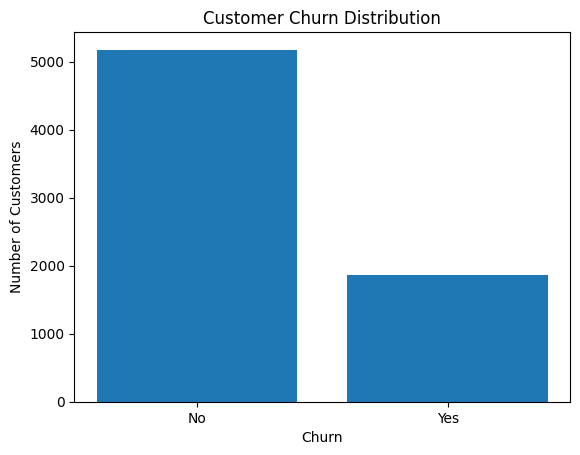

In [89]:
churn_counts = df["Churn"].value_counts()

plt.bar(churn_counts.index, churn_counts.values)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

Shows us what value the target variable holds and how many entries are 'yes' and how many are 'no'.

# 2. Basic Data Cleaning

### Drop Unwanted Features

In [90]:
df = df.drop(columns=["customerID"])

print(df.shape)

(7043, 20)


We drop the column that uniquely identifies each customer as it offers no value when predicting if the customer stays with the provider or not. 

### Check Missing Values

In [91]:
object_columns = df.select_dtypes(include=["object"]).columns

for column in object_columns:
    blank_count = (df[column].str.strip() == "").sum()

    print(f"{column}: {blank_count} blank values")

print((df["TotalCharges"].str.strip() == "").sum())

gender: 0 blank values
Partner: 0 blank values
Dependents: 0 blank values
PhoneService: 0 blank values
MultipleLines: 0 blank values
InternetService: 0 blank values
OnlineSecurity: 0 blank values
OnlineBackup: 0 blank values
DeviceProtection: 0 blank values
TechSupport: 0 blank values
StreamingTV: 0 blank values
StreamingMovies: 0 blank values
Contract: 0 blank values
PaperlessBilling: 0 blank values
PaymentMethod: 0 blank values
TotalCharges: 11 blank values
Churn: 0 blank values
11


In [92]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

print(df.isnull().sum())

gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64


In [93]:
df = df.dropna(subset=["TotalCharges"])

print("Remaining rows:", len(df))

Remaining rows: 7032


We find that we have 11 entries in the column MonthlyCharges that have missing values. Since these values are blank, I choose to get rid of the rows.

In [94]:
print(df.isnull().sum())

gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


Rechecking the row count for missing values after dropping the 11 missing in MonthlyCharges to confirm that the missing values were droped.

### Remove Duplicates

In [95]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 22


In [96]:
df = df.drop_duplicates()

print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


There can be seen 22 duplicate rows, so we remove them.

### Check Categorical Variables for Inconsistent Inputs

In [97]:
categorical_columns = df.select_dtypes(
    include=["object"]
).columns

for column in categorical_columns:
    print(f"{column}: {df[column].unique()}")

gender: ['Female' 'Male']
Partner: ['Yes' 'No']
Dependents: ['No' 'Yes']
PhoneService: ['No' 'Yes']
MultipleLines: ['No phone service' 'No' 'Yes']
InternetService: ['DSL' 'Fiber optic' 'No']
OnlineSecurity: ['No' 'Yes' 'No internet service']
OnlineBackup: ['Yes' 'No' 'No internet service']
DeviceProtection: ['No' 'Yes' 'No internet service']
TechSupport: ['No' 'Yes' 'No internet service']
StreamingTV: ['No' 'Yes' 'No internet service']
StreamingMovies: ['No' 'Yes' 'No internet service']
Contract: ['Month-to-month' 'One year' 'Two year']
PaperlessBilling: ['Yes' 'No']
PaymentMethod: ['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (automatic)']
Churn: ['No' 'Yes']


Each category has consistent outputs following an output from a list of 2 or 3 options.

In [98]:
for column in categorical_columns:
    df[column] = df[column].str.strip()

Here a strip is applied to all values to ensure that there is no error when they were entered like entering them with a extra white-space.

### Transform Categorical Variables into Numeric

In [99]:
df['gender'] = df['gender'].map({'Male': 1, 'Female': 0})
df['Partner'] = df['Partner'].map({'Yes': 1, 'No': 0})
df['Dependents'] = df['Dependents'].map({'Yes': 1, 'No': 0})
df['PhoneService'] = df['PhoneService'].map({'Yes': 1, 'No': 0})
df['PaperlessBilling'] = df['PaperlessBilling'].map({'Yes': 1, 'No': 0})
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

Transform two valued columns into binary values. We do this so that we can easily compare them to the target varaible as it also uses binary values.

In [100]:
df['MultipleLines'] = df['MultipleLines'].map({'No phone service': 0, 'No': 1, 'Yes': 2})
df['InternetService'] = df['InternetService'].map({'No': 0, 'DSL': 1, 'Fiber optic': 2})

internet_columns = [
    'OnlineSecurity',
    'OnlineBackup',
    'DeviceProtection',
    'TechSupport',
    'StreamingTV',
    'StreamingMovies'
]

for column in internet_columns:
    df[column] = df[column].map({'No internet service': 0, 'No': 1, 'Yes': 2})

df['Contract'] = df['Contract'].map({'Month-to-month': 0, 'One year': 1, 'Two year': 2})

df['PaymentMethod'] = df['PaymentMethod'].map({'Electronic check': 0, 'Mailed check': 1, 'Bank transfer (automatic)': 2, 'Credit card (automatic)': 3})

Multiple valued categories are given a numbered order (0-4) to transform their columns into numerical values. These features will need to be later transformed into dummy variables.

### Use Boxplots to Identify Outlier

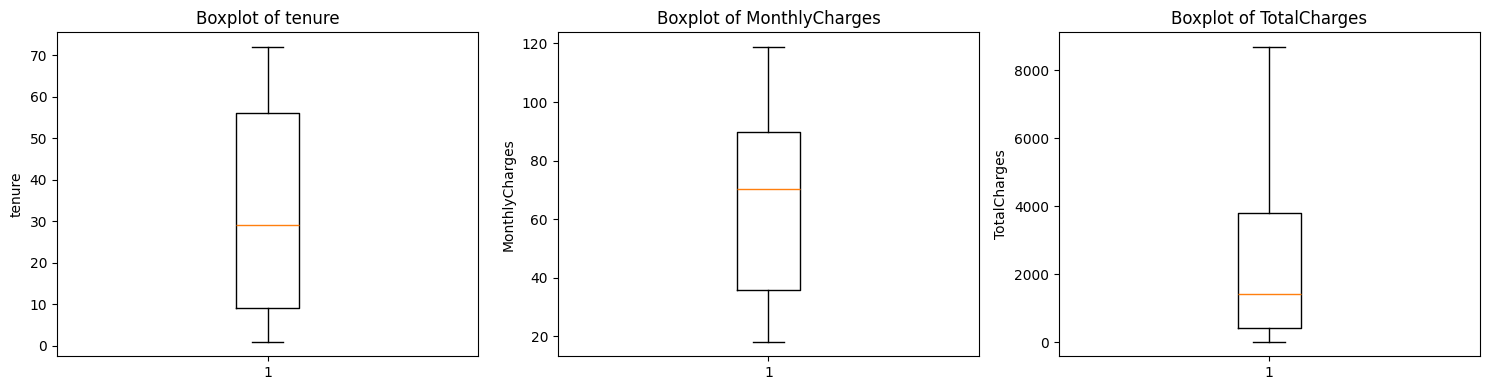

In [101]:
numeric_columns = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, column in enumerate(numeric_columns):
    axes[i].boxplot(df[column])
    axes[i].set_title(f"Boxplot of {column}")
    axes[i].set_ylabel(column)

plt.tight_layout()
plt.show()

We only analzye the numerical value columns which are TotalCharges, MonthlyCharges, and Tenure. There is no noticiable outliers within these boxplots.

# 3. Feature Engineering

### Feature Selection

In [102]:
X = df.drop(columns=['Churn'])

y = df['Churn']

In [103]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

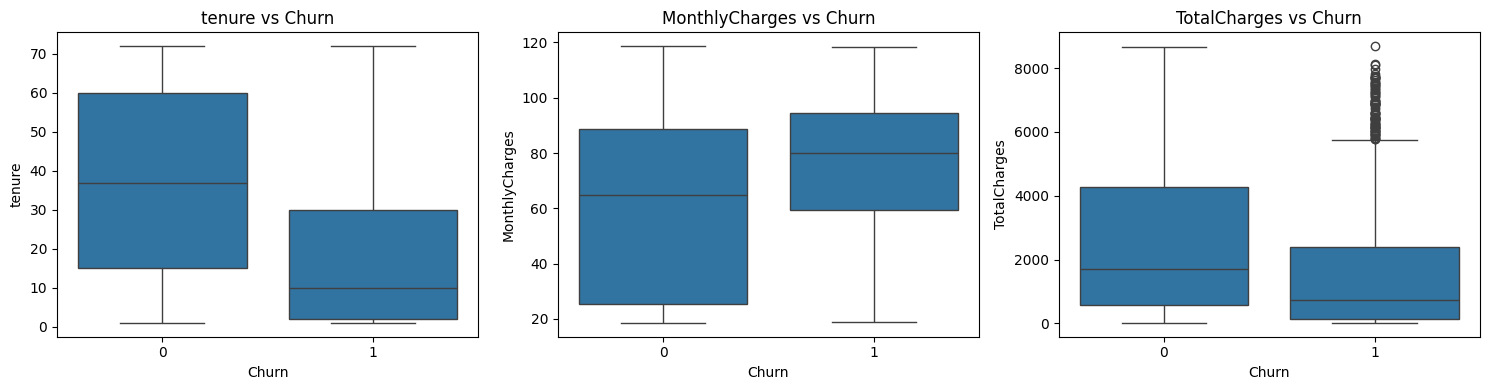

In [104]:
import matplotlib.pyplot as plt
import seaborn as sns

numeric_columns = [
    'tenure',
    'MonthlyCharges',
    'TotalCharges'
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, column in enumerate(numeric_columns):
    sns.boxplot(
        x=y_train,
        y=X_train[column],
        ax=axes[i]
    )

    axes[i].set_title(f'{column} vs Churn')
    axes[i].set_xlabel('Churn')
    axes[i].set_ylabel(column)

plt.tight_layout()
plt.show()

Here we can compare the natural numerical features to the target variable. Through these boxplots, one can see that customers who churn have shorter tenures, higher monthly charges, and lower total charges than customers that stayed with the provider. 

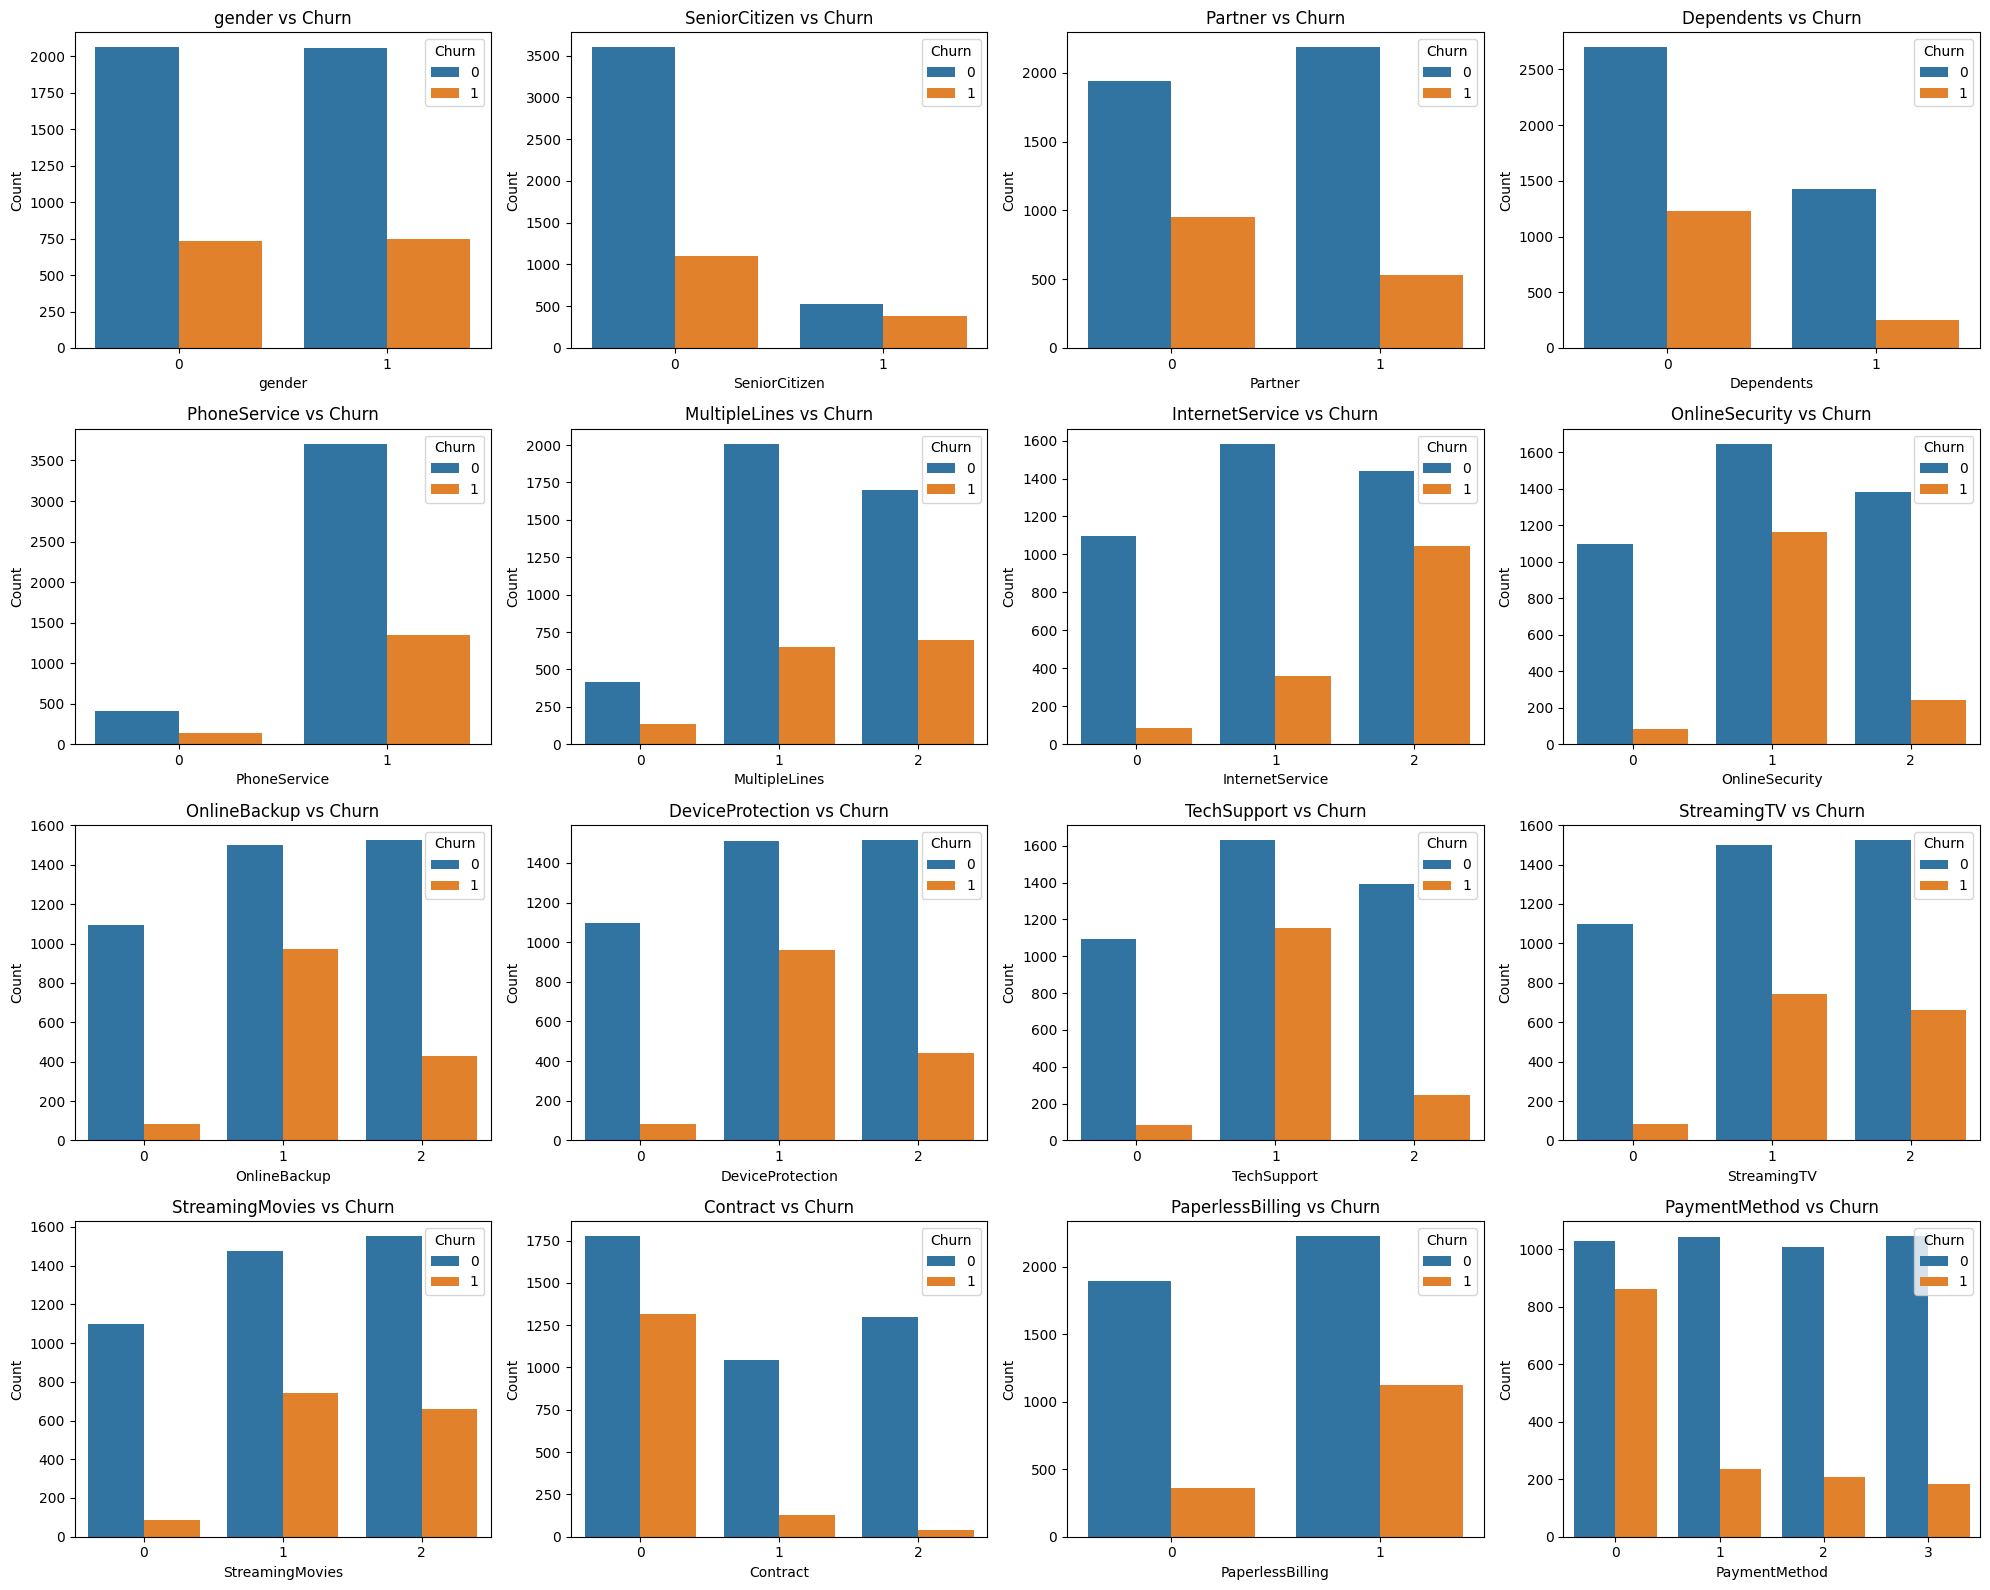

In [105]:
categorical_columns = [
    'gender',
    'SeniorCitizen',
    'Partner',
    'Dependents',
    'PhoneService',
    'MultipleLines',
    'InternetService',
    'OnlineSecurity',
    'OnlineBackup',
    'DeviceProtection',
    'TechSupport',
    'StreamingTV',
    'StreamingMovies',
    'Contract',
    'PaperlessBilling',
    'PaymentMethod'
]

fig, axes = plt.subplots(4, 4, figsize=(20, 16))

for i, column in enumerate(categorical_columns):
    sns.countplot(
        x=X_train[column],
        hue=y_train,
        ax=axes.flat[i]
    )

    axes.flat[i].set_title(f'{column} vs Churn')
    axes.flat[i].set_xlabel(column)
    axes.flat[i].set_ylabel('Count')

plt.tight_layout()
plt.show()

These grouped barplots show the categorical variables compared to if a customer churned or not. These graphs above allow us to look at each category and compare the porportion of customers who churned within each category. For example, one can see in phone service that more customers churned after using the phone service than customers who did not use the phone service. The features with a big difference in the porportions of customers that churn are features that should be included in our prediction model as they contain useful predictive information. Features with similar porportions of customers that churn should be looked at and considered for removal from the prediction model. For example, gender has nearly identical churn amounts for both genders, this is an indicator that there is little to no association between gender and the target variable churn.

In [108]:
churn_correlations = X_train.corrwith(y_train)

churn_correlations = churn_correlations.reindex(
    churn_correlations.abs().sort_values(ascending=False).index
)

print(churn_correlations)

Contract           -0.393702
tenure             -0.344066
InternetService     0.319671
PaymentMethod      -0.266990
MonthlyCharges      0.197180
PaperlessBilling    0.194910
TotalCharges       -0.190578
Dependents         -0.168416
StreamingTV         0.166046
StreamingMovies     0.161774
SeniorCitizen       0.159496
Partner            -0.151358
DeviceProtection    0.082680
OnlineBackup        0.076237
MultipleLines       0.045127
TechSupport         0.024263
OnlineSecurity      0.022675
PhoneService        0.013230
gender              0.003778
dtype: float64


The correlation values above where all calculated to show the correlation between the feature and the target variable churn. We have about features that are in the negatives. This means that as the value in the feature increases, there less likely the customer is to churn. The strongest negative correlations that are exhibited are from Contract with a -0.39, tenure with a -0.34, and payment method with a -0.26. As Contract is the highest negative correlation with churn, this means that if a customer upgrades from a month-to-month contract to a year-to-year contract, the less likely they are too churn. The clear strongest positive correlation that is exhibited comes from Internet Service with a 0.31 this means that customers that upgraded from no-internet to DSL or DSL to fiber optic had a greater likelyhood to churn. There are a few features that are below 0.05 being multiple lines, tech support, online security, phone service, and gender. These features' correlation values are very close to zero. This indicateds that they have very little linear realtionship with the target variable churn. 

In [109]:
from sklearn.feature_selection import f_classif

numeric_columns = [
    'tenure',
    'MonthlyCharges',
    'TotalCharges'
]

# Perform ANOVA
f_scores, p_values = f_classif(
    X_train[numeric_columns],
    y_train
)

# Display results
anova_results = pd.DataFrame({
    'Feature': numeric_columns,
    'F-Score': f_scores,
    'P-Value': p_values
})

print(anova_results.sort_values('P-Value'))

          Feature     F-Score        P-Value
0          tenure  752.760173  1.294296e-155
1  MonthlyCharges  226.777892   2.861560e-50
2    TotalCharges  211.282618   5.122644e-47


The anova test was performed on the three numerical features in the datasets: Tenure, MonthlyCharges, and TotalCharges. The anova test compares the mean feature values of customers who stayed to those who churned. The f-score is calculated by dividing the between group variation by the within group variation. The between group variation is the comparision of the feature averages of customers who churn and those who did not churn. For the feature tenure, this would be how different the average tenure of customer would be from those who churned and those who stayed. Within group variation is how much the feature values differ among customers within each churn group. For the feature tenure, this would be how much the tenure values differ among each churn group. 

The higher the f-score means that there is a big difference between customers who churned and customers who stayed. This makes features with high f-scores valueable and should be included in our prediction model as a bigger difference between customers that churned and did not churn will allow our model to more easily predict correctly. This means the feature tenure, monthly charges, and total charges should be kept as they boast high f-scores of 752, 226, and 211.

P-values tell how if there is a significant difference in the means of the groups you are comparing. If a p-value is less than 0.05, this means that the mean values you are comparing have a significant difference. This difference is extremely useful in prediction models and backs the choice of keeping these features as they have very small p-values of 1.2e-155, 2.8e-50, and 5.1e-47. 

In [110]:
from sklearn.feature_selection import SelectKBest, chi2

categorical_columns = [
    'gender', 'SeniorCitizen', 'Partner', 'Dependents',
    'PhoneService', 'MultipleLines', 'InternetService',
    'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
    'TechSupport', 'StreamingTV', 'StreamingMovies',
    'Contract', 'PaperlessBilling', 'PaymentMethod'
]

x = X_train[categorical_columns]
y = y_train

chi = SelectKBest(score_func=chi2, k='all')
catFeatures = chi.fit(x, y)

chi_results = pd.DataFrame({
    'Feature': categorical_columns,
    'Chi-Square': catFeatures.scores_,
    'P-Value': catFeatures.pvalues_
})

print(chi_results.sort_values('P-Value'))

             Feature  Chi-Square        P-Value
13          Contract  875.254044  2.351676e-192
15     PaymentMethod  403.168695   1.125010e-89
6    InternetService  278.645576   1.481669e-62
1      SeniorCitizen  119.486927   8.193354e-28
3         Dependents  111.441296   4.736240e-26
14  PaperlessBilling   85.667517   2.128813e-20
11       StreamingTV   74.466904   6.166341e-18
12   StreamingMovies   70.777093   3.999542e-17
2            Partner   66.207377   4.058905e-16
9   DeviceProtection   18.186825   2.002594e-05
8       OnlineBackup   15.461492   8.420340e-05
5      MultipleLines    3.582639   5.838633e-02
10       TechSupport    1.514313   2.184821e-01
7     OnlineSecurity    1.318492   2.508629e-01
4       PhoneService    0.096265   7.563581e-01
0             gender    0.039950   8.415777e-01


The chi-squared test was performed on the categorical features to determine close association between the features and the target variable. The chi-squared value is calculated by taking the actual number of customers in that category and subtracting it by the number of customers that would be expected in the category if the feature and churn were unrelated. This value is then squared and divided by the expected number of customers that would be expected in the category if the feature and churn were unrelated. This calculation is done per cell and adds the results of each cell in the category. 

A higher chi-squared value means that there is a bigger difference between the expected and actual counts. This is generally better for prediction models as a bigger difference will allow for our model to easily differentiate between customers who churn and customers who stay.

Just like in the anova test, p-values tell how if there is a significant difference in the means of the groups you are comparing. If a p-value is less than 0.05, this means that the mean values you are comparing have a significant difference. The features that exhibit a less than 0.05 p-value also have a 15 or above chi squared value. The features that exhibit a greater than 0.05 p-value also have low chi-squared values at around 0. The features gender, phone service, multiple lines, online security, and tech support all exhibit greater than 0.05 p-values indicating that there is not a big difference between the means of the groups we are comparing. These features also have a very low chi-squared values at around 0 meaning that there is no difference between the expected and actual counts for that feature. Because these features exhibit a high p-value and a low chi-squared value, I believe that they should be removed from the model.

In [111]:
features_to_remove = chi_results.loc[
    chi_results['P-Value'] > 0.05,
    'Feature'
].tolist()

print("Features to remove:", features_to_remove)

Features to remove: ['gender', 'PhoneService', 'MultipleLines', 'OnlineSecurity', 'TechSupport']


In [112]:
X_train_selected = X_train.drop(
    columns=features_to_remove
)

X_test_selected = X_test.drop(
    columns=features_to_remove
)

The chi-squared test showed that the following features should be removed: MultipleLines, TechSupport, OnlineSecurity, PhoneService, and gender. These features were chosen to be removed as the chi-squared test revealed that these features had a greater than 0.05 p-value and a low chi-squared value.

The current results are dominated by the three multivalued features. These features need to be split into dummy variables. 

In [113]:
from sklearn.feature_selection import VarianceThreshold

selector = VarianceThreshold(threshold=0)

selector.fit(X_train)

zero_variance_columns = X_train.columns[
    ~selector.get_support()
]

print("Zero variance features:")
print(zero_variance_columns.tolist())

Zero variance features:
[]


There is no features with every row having the exact same value or zero variance features.

The algorithm I chose was logistic Regression as my classification algorithm. I chose Logistic Regression because the target variable and most of my feature variables use binary values (0 and 1). While logistic regression does not require standardized data, it would improve the results of the model. This is because the numerical features that do not use binary values have numerous ranges in their values. This can be apparent in features such as monthly charges and total charges as they each have numerous different charges per customer.

In [115]:
from sklearn.preprocessing import StandardScaler

numeric_columns = [
    'tenure',
    'MonthlyCharges',
    'TotalCharges'
]

scaler = StandardScaler()

X_train_scaled = X_train_selected.copy()
X_test_scaled = X_test_selected.copy()

X_train_scaled[numeric_columns] = scaler.fit_transform(
    X_train_selected[numeric_columns]
)

X_test_scaled[numeric_columns] = scaler.transform(
    X_test_selected[numeric_columns]
)

In [116]:
print(X_train_scaled[numeric_columns].describe())

             tenure  MonthlyCharges  TotalCharges
count  5.608000e+03    5.608000e+03   5608.000000
mean   8.489009e-17    1.659791e-16      0.000000
std    1.000089e+00    1.000089e+00      1.000089
min   -1.287204e+00   -1.556640e+00     -1.005450
25%   -9.593558e-01   -8.778982e-01     -0.830221
50%   -1.397358e-01    1.821397e-01     -0.392241
75%    9.257700e-01    8.295930e-01      0.673783
max    1.622447e+00    1.784086e+00      2.818236


Features that must be removed were deternined from our anova and chi tests. The anova test showed that all of our numerical features have high f-scores with p-values less than or equal to 0.05. The chi-squared test showed that the following features should be removed: MultipleLines, TechSupport, OnlineSecurity, PhoneService, and gender. These features were chosen to be removed as the chi-squared test revealed that these features had a greater than 0.05 p-value and a low chi-squared value.

With many variables having multiple values, they must be split into different sub features or dummy variables. The following features are multi-valued and must be split into dummy variables: MultipleLines, InternetService, OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies, Contract, and PaymentMethod.

In [117]:
dummy_columns = [
    'MultipleLines',
    'InternetService',
    'OnlineSecurity',
    'OnlineBackup',
    'DeviceProtection',
    'TechSupport',
    'StreamingTV',
    'StreamingMovies',
    'Contract',
    'PaymentMethod'
]

# Only encode columns that were retained
dummy_columns = [
    column for column in dummy_columns
    if column in X_train_selected.columns
]

X_train_final = pd.get_dummies(
    X_train_scaled,
    columns=dummy_columns,
    dtype=int
)

X_test_final = pd.get_dummies(
    X_test_scaled,
    columns=dummy_columns,
    dtype=int
)

# Ensure training and testing have identical columns
X_test_final = X_test_final.reindex(
    columns=X_train_final.columns,
    fill_value=0
)

# 4. Build the Model

#### Does this data need to be balanced?

Yes, this dataset needs to be balanced as the target variable is imbalanced. This can be seen in earlier data cleaning and analysis of the target variable as the churn column holds over 5000 no selections and just under 2000 yes selections.

In [118]:
from imblearn.over_sampling import SMOTE

# Create SMOTE oversampler
smote = SMOTE(random_state=42)

# Balance training data
X_train_balanced, y_train_balanced = smote.fit_resample(
    X_train_final,
    y_train
)

print("Before balancing:", X_train_final.shape)
print("After balancing:", X_train_balanced.shape)

print("\nBefore:")
print(y_train.value_counts())

print("\nAfter:")
print(y_train_balanced.value_counts())

Before balancing: (5608, 29)
After balancing: (8244, 29)

Before:
Churn
0    4122
1    1486
Name: count, dtype: int64

After:
Churn
0    4122
1    4122
Name: count, dtype: int64


#### Do you use train_test_split or cross validation to validate the result?

I choose a train test split approach to validate the result. I split the data 80% of the data for training and 20% of the data for testing.

#### Which algorithm is appropriate for this problem?

I believe that logistic regression is the most appropriate because the target variable "chur" use binary values of 0 and 1.

In [120]:
print(X_train_final.columns.tolist())

['SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PaperlessBilling', 'MonthlyCharges', 'TotalCharges', 'InternetService_0', 'InternetService_1', 'InternetService_2', 'OnlineBackup_0', 'OnlineBackup_1', 'OnlineBackup_2', 'DeviceProtection_0', 'DeviceProtection_1', 'DeviceProtection_2', 'StreamingTV_0', 'StreamingTV_1', 'StreamingTV_2', 'StreamingMovies_0', 'StreamingMovies_1', 'StreamingMovies_2', 'Contract_0', 'Contract_1', 'Contract_2', 'PaymentMethod_0', 'PaymentMethod_1', 'PaymentMethod_2', 'PaymentMethod_3']


In [121]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train_balanced, y_train_balanced)

y_pred = model.predict(X_test_final)

#### Which metrics do you use to evaluate the prediction model?


In [122]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

Accuracy: 0.7553495007132668
Precision: 0.5272373540856031
Recall: 0.7304582210242587
F1 Score: 0.6124293785310735


In [123]:
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.76      0.82      1031
           1       0.53      0.73      0.61       371

    accuracy                           0.76      1402
   macro avg       0.71      0.75      0.72      1402
weighted avg       0.79      0.76      0.77      1402



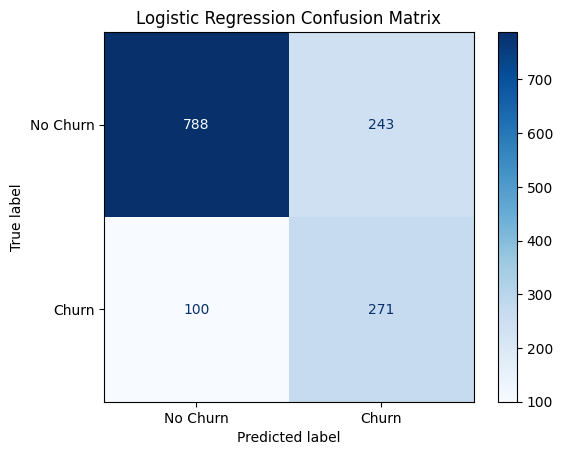

In [124]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=['No Churn', 'Churn'],
    cmap='Blues'
)

plt.title("Logistic Regression Confusion Matrix")
plt.show()

The metrics that we used to evaluate the model was accuracy, precision, recall, f1-score, a classification report that displays all the prior metrics together, and a confusion matrix. The accuracy metric is the percentage of all the predictions that are correct. The Accuracy of this model ended up being 75.5%. The precision metric is the percentage of customers predicted to leave, how many actually left. The precision of the model ended up being 52.7%. The recall metric is the percentage of custromers who actually left, how many did the model correctly identify. The recall of the model ended up being 73%. The f1-score is a score that combines the precision and recall metric by the equaltion F1 Score = 2 x (Precision x Recall / Precision + Recall).

#### If the accuracy score or r-squared score is low, generally it is considered as a bad model. Explain why your model failed. 


Since the model is using a logistic regression algorithm, the r-squared does not apply. However, the accuracy of the model was seen as 75.5%. While this is not a extremely high accuracy score, I would not categorize this model as a failure as 75.5% is moderately high given the dataset. Since what we are predicting is not something that we must predict with the highest accuracy, like predictions done in the medical field, we can afford this difference between predictions. The model is fairly consistent with its predictions as it has a relatively high recall at 73% (correctly identifying customers who actually churned). Overall, I feel as though the model preformed moderately well.

One weakness that this model exhibits is a low precision score of 52.7%. This means that the model incorrectly predicted that customers would churn when they ended up staying with the provider. One possibility for this could be how I chose to balance the data through SMOTE (Synthetic Minority Oversampling Technique). Smote balances the data through creating new data points based on existing data points of the minority class. Smote creates new data points until the both classes have around the same number of observations. While adding these new data points, the model became more focused on the class that was recieving all the new data points and was more likely to predict that a customer would churn.  